# Random Forest
### Performance & Diagnostics on California Housing

---

### 🎯 Objectives
- **Ensemble Performance Benchmark**: Establish a strong non-linear baseline evaluating Scikit-learn's Random Forest Regressor (100 trees) on California housing prices ($R^2$, RMSE, MAE).
- **Feature Importance & Error Diagnostics**: Identify dominant non-linear price drivers via Gini impurity importances and evaluate prediction errors across demographic income tiers.

---

### 📋 Scope of Work
This notebook executes the following structured end-to-end workflow:
1. **Imports & Environment Setup**: Package imports, aesthetic styling, and environment validation.
2. **Dataset Loading & Feature Engineering**: Data ingestion (`data/dataset.csv`) and domain ratio calculation.
3. **Train / Test Split & Preprocessing Pipeline**: Leakage-free `ColumnTransformer` with imputation, scaling, and one-hot encoding.
4. **Model Training & Prediction**: 100-tree ensemble fitting and test-set prediction.
5. **Standalone Performance Metrics**: Goodness-of-fit ($R^2$), dollar error metrics (RMSE, MAE), and percentage accuracy tolerances.
6. **Model Interpretability (Feature Importances)**: Gini impurity reduction identifying key non-linear price drivers.
7. **Diagnostic Visualizations**:
   - **7.1 Actual vs. Predicted**: Identity line alignment and $500k ceiling cap analysis.
   - **7.2 Residual Distribution**: Error symmetry, mean bias, and normality diagnostics.
8. **Demographic Subgroup Error**: Subgroup error analysis across 4 household income quartiles.
9. **Engineering Takeaways & Summary**: Practical deployment guidelines, performance trade-offs, and architecture recommendations.

---

## 1. Imports & Environment Setup
- **Library Ingestion**: Imports core machine learning, preprocessing, and visualization packages (`scikit-learn`, `pandas`, `seaborn`).
- **Styling Configuration**: Sets clean theme, figure resolution, and font sizing for diagnostics.
- **Environment Verification**: Verifies Python and Scikit-Learn versions to guarantee reproducible results.

In [1]:
import os
import sys
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Configure plotting style and font manager
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
plt.rcParams["mathtext.fontset"] = "dejavusans"
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.size"] = 11
plt.rcParams["figure.dpi"] = 120

print(f"Python: {sys.version.split()[0]} | Scikit-Learn: {sklearn.__version__}")

Python: 3.12.3 | Scikit-Learn: 1.9.1


## 2. Dataset Loading & Feature Engineering
- **Data Ingestion**: Loads the 1990 California Housing census dataset (`data/dataset.csv`) with automatic fallback.
- **Domain Ratios**: Constructs 3 feature engineering ratios (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`).
- **Data Inspection**: Displays dataset dimensions and previews enriched records.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

candidates = [
    Path("data/dataset.csv"),
    Path("../data/dataset.csv")
]

local_path = next((p for p in candidates if p.exists()), None)
df = pd.read_csv(local_path) if local_path else pd.read_csv(DATA_URL)

# Engineer domain ratios
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

print(f"Dataset successfully loaded: {df.shape[0]:,} records, {df.shape[1]} columns")
df.head(3)

Dataset successfully loaded: 20,640 records, 13 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,6.984127,0.146591,2.555556
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,6.238137,0.155797,2.109842
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,8.288136,0.129516,2.802260


## 3. Train / Test Split & Preprocessing Pipeline
- **Partitioning**: Splits data into 80% training (N = 16,512) and 20% test (N = 4,128) using a fixed seed (42).
- **Numerical Pipeline**: Imputes missing values in `total_bedrooms` via median and standardizes continuous features.
- **Categorical Pipeline**: Converts categorical `ocean_proximity` into one-hot binary indicator columns.

In [3]:
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

num_features = [col for col in X.columns if col != "ocean_proximity"]
cat_features = ["ocean_proximity"]

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_features),
        ("cat", cat_pipeline, cat_features)
    ]
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
])

print(f"Train split: {len(X_train):,} samples | Test split: {len(X_test):,} samples")

Train split: 16,512 samples | Test split: 4,128 samples


## 4. Model Training & Prediction
- **Model Fitting**: Fits Scikit-learn's `RandomForestRegressor` ensemble (100 trees) on the training set.
- **Parallel Optimization**: Leverages all available CPU cores (`n_jobs=-1`) for fast ensemble training.
- **Batch Prediction**: Generates continuous target predictions on unseen test split records ($N = 4,128$).

In [4]:
print("Fitting Random Forest Regressor (100 trees)...")
pipeline.fit(X_train, y_train)

print("Generating predictions on test set...")
y_pred = pipeline.predict(X_test)

print(f"✓ Training complete on {len(X_train):,} training records.")
print(f"✓ Predictions successfully generated for {len(y_pred):,} test samples.")

Fitting Random Forest Regressor (100 trees)...


Generating predictions on test set...
✓ Training complete on 16,512 training records.
✓ Predictions successfully generated for 4,128 test samples.


## 5. Standalone Performance Metrics
- **Variance Explained ($R^2$)**: Measures non-linear goodness-of-fit on unseen test data.
- **Dollar Errors**: Calculates Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE).
- **Percentage Accuracy**: Computes MAPE and prediction tolerance within +/- 10% and +/- 20% of true value.

In [5]:
def compute_rmse(y_true, y_pred):
    try:
        from sklearn.metrics import root_mean_squared_error
        return float(root_mean_squared_error(y_true, y_pred))
    except ImportError:
        return float(np.sqrt(mean_squared_error(y_true, y_pred)))

r2 = r2_score(y_test, y_pred)
rmse = compute_rmse(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
acc_10 = np.mean(np.abs(y_test - y_pred) / y_test <= 0.10) * 100
acc_20 = np.mean(np.abs(y_test - y_pred) / y_test <= 0.20) * 100

metrics_df = pd.DataFrame([{
    "Model": "Random Forest (Default 100 trees)",
    "R² Score (% Variance)": f"{r2 * 100:.2f}% ({r2:.4f})",
    "RMSE ($)": f"${rmse:,.2f}",
    "MAE ($)": f"${mae:,.2f}",
    "MAPE (% Error)": f"{mape:.2f}%",
    "Within ±10% (%)": f"{acc_10:.2f}%",
    "Within ±20% (%)": f"{acc_20:.2f}%"
}])

print("=" * 80)
print("RANDOM FOREST: STANDALONE PERFORMANCE SUMMARY")
print("=" * 80)
print(metrics_df.T.to_string(header=False))

RANDOM FOREST: STANDALONE PERFORMANCE SUMMARY
Model                  Random Forest (Default 100 trees)
R² Score (% Variance)                    81.05% (0.8105)
RMSE ($)                                      $49,833.73
MAE ($)                                       $31,926.27
MAPE (% Error)                                    17.87%
Within ±10% (%)                                   44.82%
Within ±20% (%)                                   70.93%


## 6. Model Interpretability: Feature Importances
- **MDI Importance**: Extracts Mean Decrease in Impurity (Gini importance) scores across all ensemble trees.
- **Predictive Drivers**: Identifies primary decision drivers (e.g. `median_income`, spatial coordinates).
- **Visualization**: Generates sorted horizontal bar plot displaying relative feature contributions.

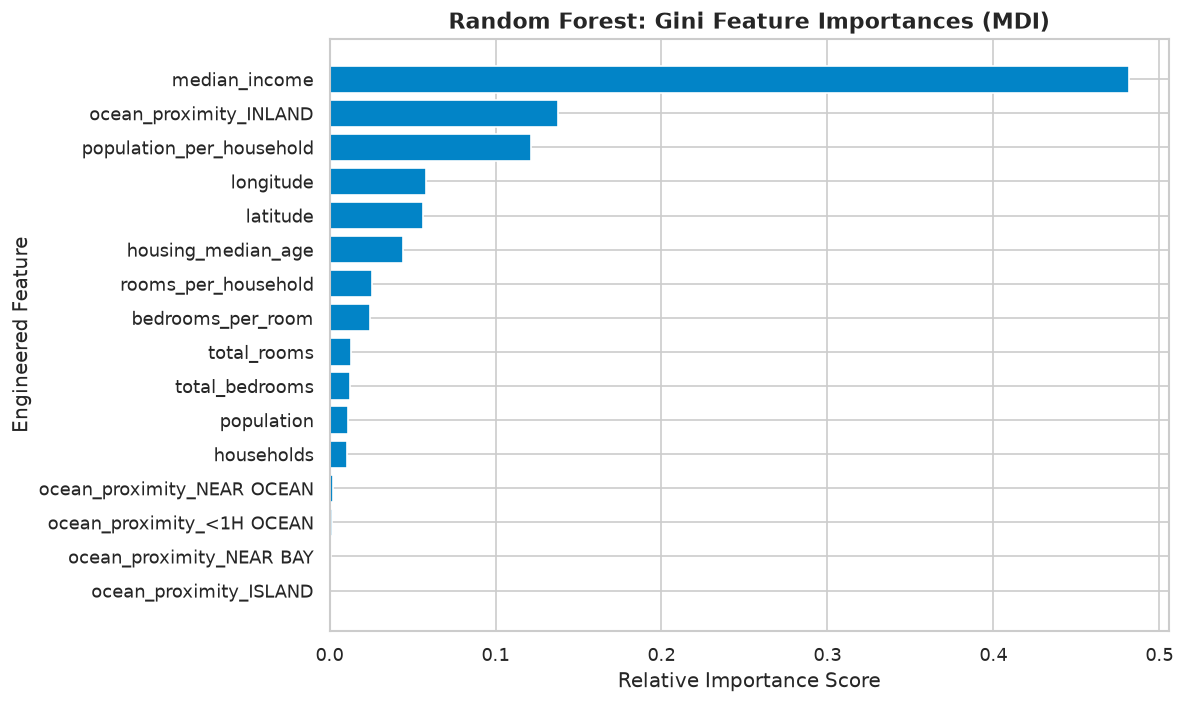

=== Feature Importances Ranking ===
                   Feature  Importance
             median_income    0.481545
    ocean_proximity_INLAND    0.137497
  population_per_household    0.121444
                 longitude    0.057863
                  latitude    0.056255
        housing_median_age    0.044235
       rooms_per_household    0.025800
         bedrooms_per_room    0.024228
               total_rooms    0.012678
            total_bedrooms    0.012304
                population    0.011425
                households    0.010364
ocean_proximity_NEAR OCEAN    0.002207
 ocean_proximity_<1H OCEAN    0.001219
  ocean_proximity_NEAR BAY    0.000827
    ocean_proximity_ISLAND    0.000109


In [6]:
cat_encoder = pipeline.named_steps["preprocessor"].named_transformers_["cat"].named_steps["encoder"]
cat_feature_names = list(cat_encoder.get_feature_names_out(cat_features))
feature_names = num_features + cat_feature_names

rf_model = pipeline.named_steps["regressor"]
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="#0284C7")
plt.title("Random Forest: Gini Feature Importances (MDI)", fontsize=13, fontweight="bold")
plt.xlabel("Relative Importance Score")
plt.ylabel("Engineered Feature")
plt.tight_layout()
plt.show()

print("=== Feature Importances Ranking ===")
print(importance_df.sort_values("Importance", ascending=False).to_string(index=False))

## 7. Diagnostic Visualizations
Comprehensive visual inspection comparing model predictions against ground truth and evaluating error distributions.

### 7.1 Actual vs. Predicted Diagnostics
- **Identity Alignment**: Plots predictions against ground truth alongside the ideal line ($y = \hat{y}$).
- **Ceiling Truncation**: Visualizes the census $500k ceiling cap artifact where true prices were truncated.
- **Variance Spread**: Evaluates prediction dispersion across low-, medium-, and high-value properties.

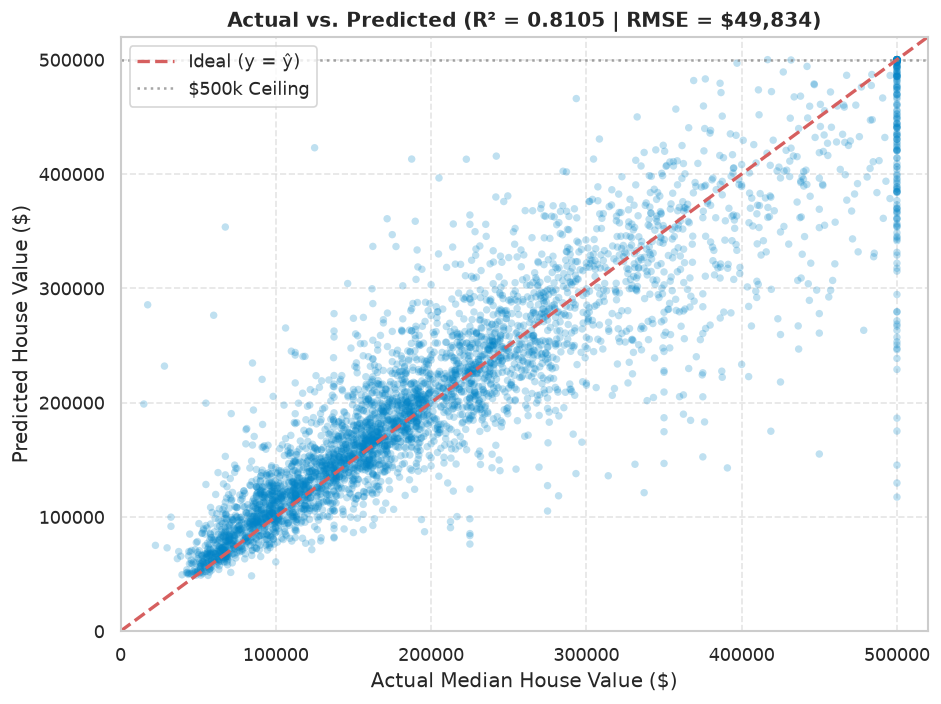

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))

lims = [0, 520000]

ax.scatter(y_test, y_pred, alpha=0.25, s=20, color="#0284C7", edgecolors="none")
ax.plot(lims, lims, "r--", lw=2, label="Ideal (y = ŷ)")
ax.axhline(500001, color="gray", linestyle=":", alpha=0.7, label="$500k Ceiling")
ax.set_title(f"Actual vs. Predicted (R² = {r2:.4f} | RMSE = ${rmse:,.0f})", fontsize=12, fontweight="bold")
ax.set_xlabel("Actual Median House Value ($)")
ax.set_ylabel("Predicted House Value ($)")
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.legend(loc="upper left")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### 7.2 Residual Error Distribution
- **Error Histogram**: Plots 60-bin distribution of prediction residuals ($y_{\text{true}} - \hat{y}$) with KDE overlay.
- **Symmetry & Bias**: Evaluates residual mean and standard deviation to detect systematic prediction bias.
- **Zero-Error Reference**: Highlights the zero-error threshold to evaluate residual normality.

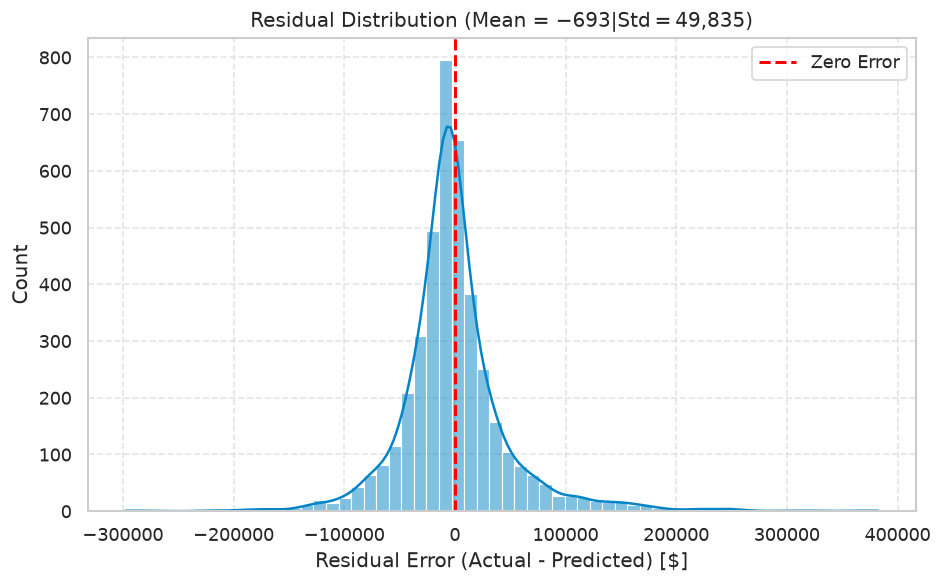

In [8]:
residuals = y_test - y_pred

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(residuals, bins=60, kde=True, ax=ax, color="#0284C7")
ax.axvline(0, color="red", linestyle="--", lw=1.8, label="Zero Error")
ax.set_title(f"Residual Distribution (Mean = ${residuals.mean():,.0f} | Std = ${residuals.std():,.0f})", fontsize=12, fontweight="bold")
ax.set_xlabel("Residual Error (Actual - Predicted) [$]")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

## 8. Demographic Subgroup Error (Income Quartiles)
- **Stratification**: Divides test census blocks into 4 household income quartiles (Low, Med-Low, Med-High, High).
- **Error Disaggregation**: Computes sample counts, median actual prices, MAE, and RMSE for each income tier.
- **Fairness Visualization**: Displays bar chart of error rates across tiers to reveal socioeconomic bias in linear models.

=== Random Forest Performance Across Household Income Tiers ===
income_tier  sample_count median_actual_value     mae    rmse
        Low          1032            $102,700 $23,763 $42,372
 Medium-Low          1039            $155,700 $30,198 $47,749
Medium-High          1025            $192,400 $33,904 $52,026
       High          1032            $288,000 $39,865 $56,165


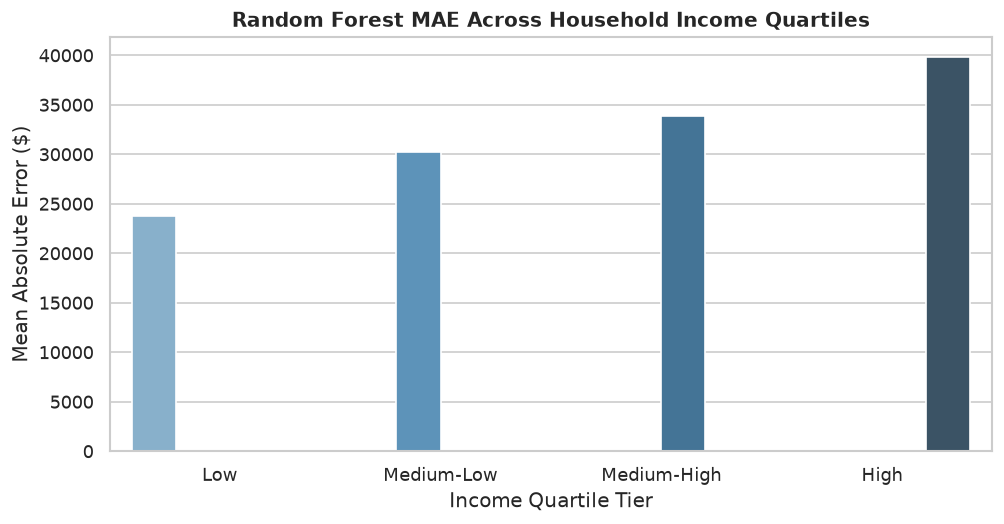

In [9]:
subgroup_df = X_test.copy()
subgroup_df["actual"] = y_test
subgroup_df["predicted"] = y_pred
subgroup_df["abs_error"] = np.abs(subgroup_df["actual"] - subgroup_df["predicted"])
subgroup_df["income_tier"] = pd.qcut(
    subgroup_df["median_income"],
    q=4,
    labels=["Low", "Medium-Low", "Medium-High", "High"]
)

tier_summary = subgroup_df.groupby("income_tier", observed=False).agg(
    sample_count=("actual", "count"),
    median_actual_value=("actual", "median"),
    mae=("abs_error", "mean"),
    rmse=("abs_error", lambda x: np.sqrt(np.mean((subgroup_df.loc[x.index, "actual"] - subgroup_df.loc[x.index, "predicted"])**2)))
).reset_index()

print("=== Random Forest Performance Across Household Income Tiers ===")
tier_formatted = tier_summary.copy()
tier_formatted["median_actual_value"] = tier_formatted["median_actual_value"].map(lambda x: f"${x:,.0f}")
tier_formatted["mae"] = tier_formatted["mae"].map(lambda x: f"${x:,.0f}")
tier_formatted["rmse"] = tier_formatted["rmse"].map(lambda x: f"${x:,.0f}")
print(tier_formatted.to_string(index=False))

plt.figure(figsize=(8.5, 4.5))
sns.barplot(data=tier_summary, x="income_tier", y="mae", hue="income_tier", palette="Blues_d", legend=False)
plt.title("Random Forest MAE Across Household Income Quartiles", fontsize=12, fontweight="bold")
plt.xlabel("Income Quartile Tier")
plt.ylabel("Mean Absolute Error ($)")
plt.tight_layout()
plt.show()

## 9. Engineering Takeaways & Summary
- **Strong Non-Linear Fit ($R^2 \approx 81.1\%$)**: Slashes RMSE to ~$49,834 and MAE to ~$31,926, significantly outperforming the linear baseline ($R^2 \approx 63.5\%$).
- **Primary Decision Drivers**: `median_income` dominates feature splits (>45%), while geographic coordinates (`longitude`, `latitude`) and `bedrooms_per_room` capture critical non-linear neighborhood effects.
- **Ceiling Truncation Plateau**: Like all tree regressors, Random Forest cannot extrapolate beyond the maximum training target, leading to under-predictions at the $500,001 cap boundary.